<a href="https://colab.research.google.com/github/R0dr1g0G0mes/Machine_Learning/blob/main/Documentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [28]:
# Install required Python libraries (
!pip install lark
!pip install numpy
!pip install shapely
!pip install mathutils
!pip install ifcopenshell

## Build an IFC Wall with an Opening and Window Using IfcOpenShell

This workflow demonstrates how to programmatically construct a basic BIM model using `ifcopenshell` and `ifcopenshell.api`.

## Create a Base IFC Model

Initializes an empty model, sets up the `IfcProject` with default elements, creates a 3D "Body" representation context, and saves the result to `model_base.ifc`.

In [29]:
import ifcopenshell
import ifcopenshell.api

# Create a brand-new empty IFC4 file in memory (can also be IFC2X3 or IFC4X3)
model = ifcopenshell.api.run("project.create_file", version="IFC4")

# Create the project container and assign standard measurement units
project = ifcopenshell.api.run("root.create_entity", model, ifc_class="IfcProject", name="Proj")
ifcopenshell.api.run("unit.assign_unit", model)

# Create the spatial hierarchy levels: Site -> Building -> Storey
site = ifcopenshell.api.run("root.create_entity", model, ifc_class="IfcSite", name="Site")
building = ifcopenshell.api.run("root.create_entity", model, ifc_class="IfcBuilding", name="Bldg")
storey = ifcopenshell.api.run("root.create_entity", model, ifc_class="IfcBuildingStorey", name="Storey")

# Link the hierarchy together from top to bottom (aggregation = parent/child structure)
ifcopenshell.api.run("aggregate.assign_object", model, products=[site], relating_object=project)
ifcopenshell.api.run("aggregate.assign_object", model, products=[building], relating_object=site)
ifcopenshell.api.run("aggregate.assign_object", model, products=[storey], relating_object=building)

# Define the 3D geometric representation context ('Body') used for 3D model geometry
ctx = ifcopenshell.api.run("context.add_context", model, context_type="Model")
body_ctx = ifcopenshell.api.run("context.add_context", model, context_type="Model", context_identifier="Body", target_view="MODEL_VIEW", parent=ctx,)

# Save the base spatial model to disk
model.write("model_base.ifc")

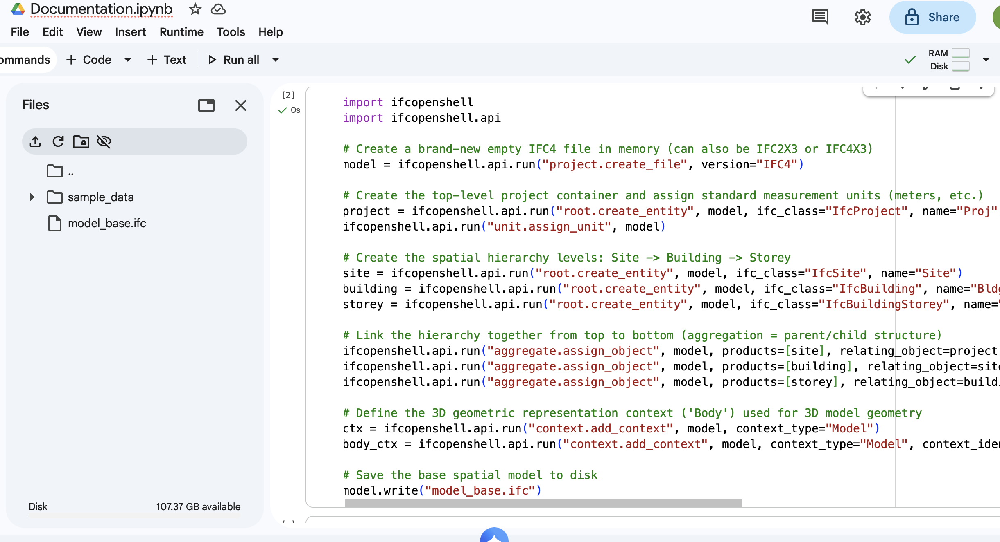

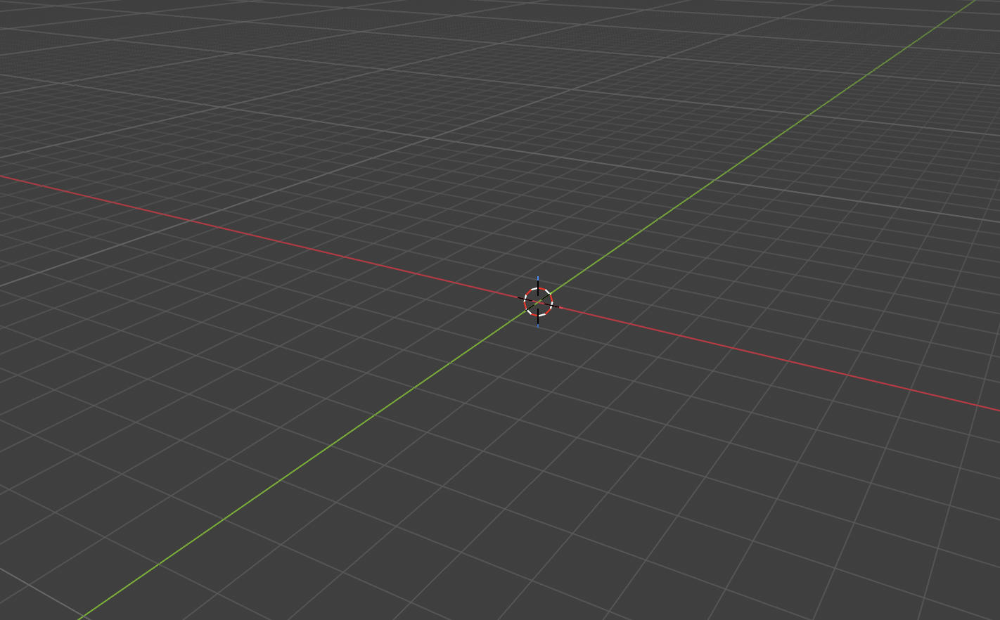

## Add Wall

Opens `model_base.ifc`, creates an `IfcWall` assigned to the storey with a 4.0 m × 2.8 m × 0.3 m representation, and saves the result as `model_wall.ifc`.

In [30]:
import ifcopenshell
import ifcopenshell.api

# Open the base IFC file created in the previous step
model = ifcopenshell.open("model_base.ifc")

# Grab the first storey and the 3D 'Body' geometry context
storey = model.by_type("IfcBuildingStorey")[0]
body_ctx = [c for c in model.by_type("IfcGeometricRepresentationSubContext") if c.ContextIdentifier == "Body"][0]

# Create a wall element and assign it to the storey so BIM tools know which level it belongs to
wall = ifcopenshell.api.run("root.create_entity", model, ifc_class="IfcWall", name="Wall")
ifcopenshell.api.run("spatial.assign_container", model, products=[wall], relating_structure=storey)

# Generate 3D wall geometry (4.0 m long, 2.8 m high, 0.3 m thick) and attach it to the wall
rep = ifcopenshell.api.run("geometry.add_wall_representation", model, context=body_ctx,
    length=4.0,
    height=2.8,
    thickness=0.3,)
ifcopenshell.api.run("geometry.assign_representation", model, product=wall, representation=rep)

# Save the updated model as a new IFC file
model.write("model_wall.ifc")

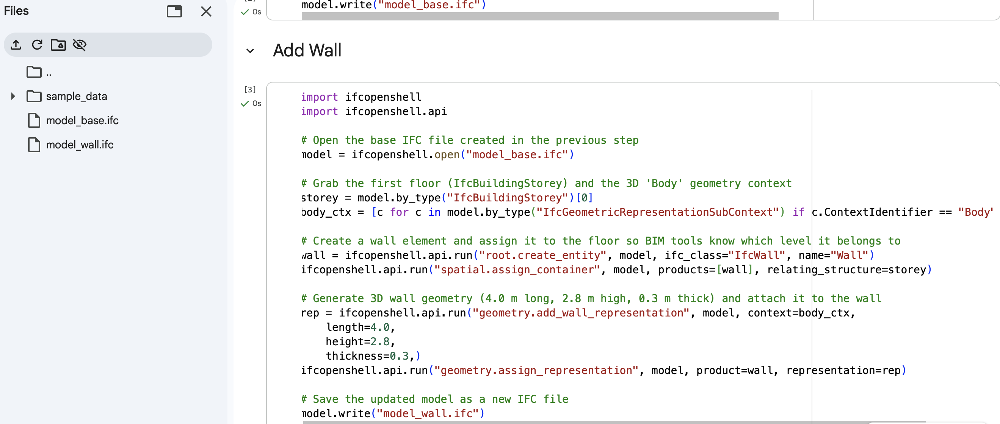

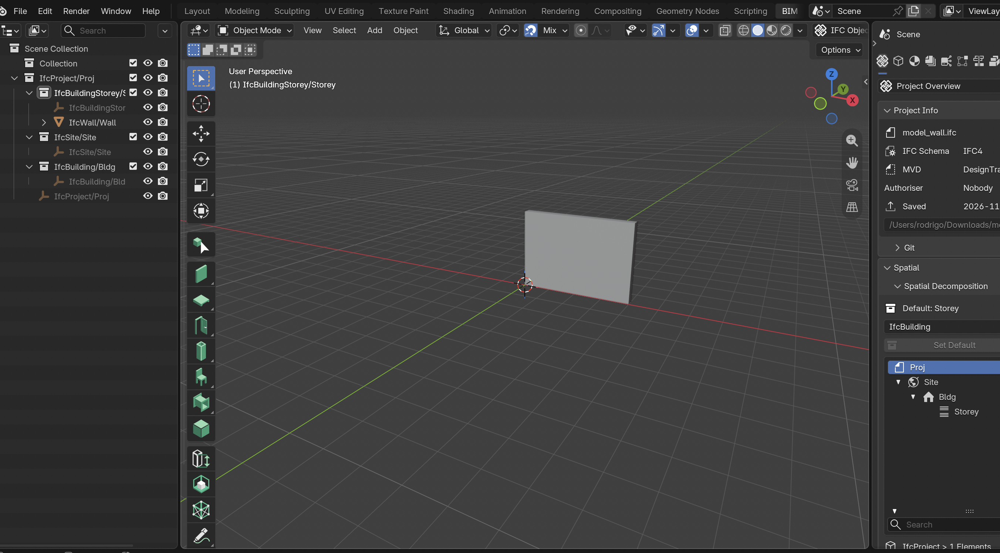

## Cut an Opening and Insert a Window

Opens `model_wall.ifc`, creates an `IfcOpeningElement` (1.2 m × 1.2 m × 0.3 m) positioned at (1.4, 0.0, 0.9) and links it to the wall via `IfcRelVoidsElement`, then creates an `IfcWindow` (1.2 m × 1.2 m × 0.12 m) at the same coordinates, links it to the opening via `IfcRelFillsElement`, and saves the final model to `model_wall_window.ifc`.

In [31]:
import ifcopenshell
import ifcopenshell.api

# Open the model that already contains the wall
model = ifcopenshell.open("model_wall.ifc")
wall = model.by_type("IfcWall")[0]
storey = model.by_type("IfcBuildingStorey")[0]
body_ctx = [ c for c in model.by_type("IfcGeometricRepresentationSubContext") if c.ContextIdentifier == "Body" ][0]

# Create the opening in the wall
opening = ifcopenshell.api.run("root.create_entity", model, ifc_class="IfcOpeningElement", name="Opening")
ifcopenshell.api.run("spatial.assign_container", model, products=[opening], relating_structure=storey)

# Define opening dimensions: 1.2 m wide, 1.2 m high, 0.3 m deep
op_rep = ifcopenshell.api.run("geometry.add_wall_representation", model, context=body_ctx,
    length=1.2,
    height=1.2,
    thickness=0.3,
)
ifcopenshell.api.run("geometry.assign_representation", model, product=opening, representation=op_rep)

# Position the opening inside the wall
ifcopenshell.api.run("geometry.edit_object_placement", model, product=opening,
    matrix=[
        [1, 0, 0, 1.4],   # X  = 1.4 m along wall length
        [0, 1, 0, 0],     # Y  = 0.0 m across wall thickness
        [0, 0, 1, 0.9],   # Z  = 0.9 m elevation
        [0, 0, 0, 1],     # [0, 0, 0, 1] standard
    ],
)

# Connect the opening to the wall that the 'opening' cuts 'wall'
model.create_entity( "IfcRelVoidsElement", GlobalId=ifcopenshell.guid.new(), RelatingBuildingElement=wall, RelatedOpeningElement=opening,
)

# Create the window and place it inside the opening
window = ifcopenshell.api.run("root.create_entity", model, ifc_class="IfcWindow", name="Window")
ifcopenshell.api.run("spatial.assign_container", model, products=[window], relating_structure=storey)

# Define window geometry: 1.2 m wide, 1.2 m high, 0.12 m frame thickness
win_rep = ifcopenshell.api.run("geometry.add_wall_representation", model, context=body_ctx,
    length=1.2,
    height=1.2,
    thickness=0.12,
)
ifcopenshell.api.run("geometry.assign_representation", model, product=window, representation=win_rep)

# Position the window inside the wall
ifcopenshell.api.run("geometry.edit_object_placement", model, product=window,
    matrix=[
        [1, 0, 0, 1.4],   # X  = 1.4 m along wall length
        [0, 1, 0, 0],     # Y  = 0.0 m across wall thickness
        [0, 0, 1, 0.9],   # Z  = 0.9 m elevation
        [0, 0, 0, 1],     # [0, 0, 0, 1] standard
    ],
)

# Connect the window to the opening, the 'window' fills 'opening'
model.create_entity("IfcRelFillsElement", GlobalId=ifcopenshell.guid.new(), RelatingOpeningElement=opening, RelatedBuildingElement=window,)

# Save the final model containing the wall, opening, and window
model.write("model_wall_window.ifc")

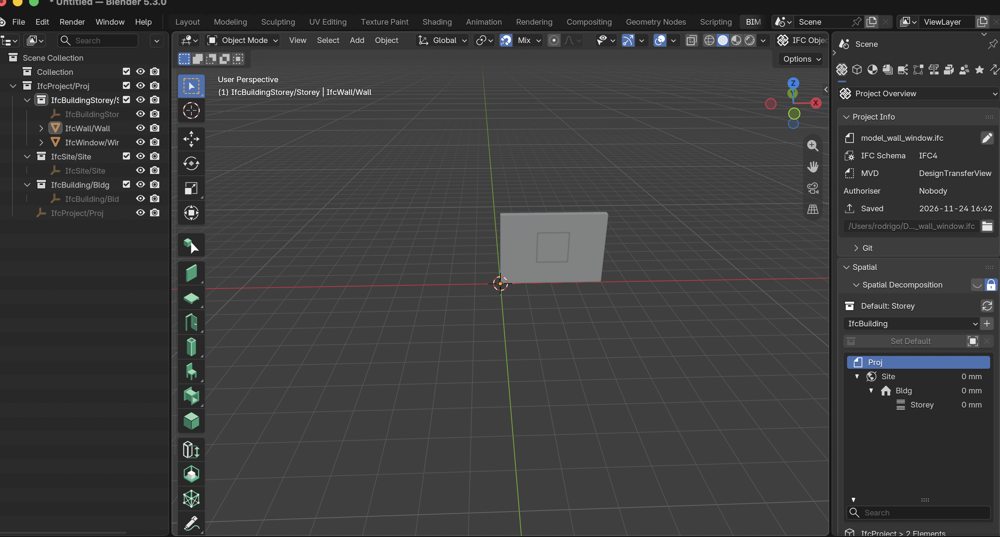

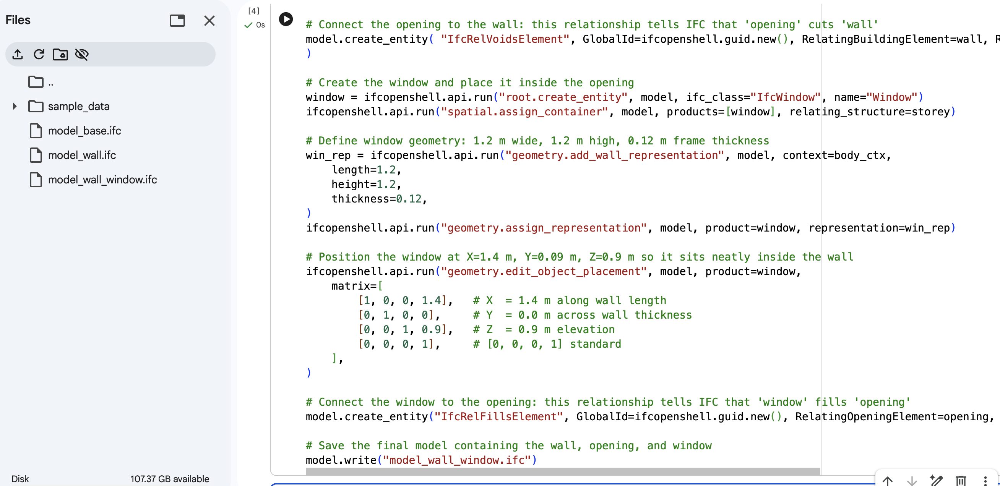

Iterates over the models and prints the IFC class type e.is_a() of every IfcProduct entity in each file.

In [32]:
# Loop through each IFC file and print the IFC class type of every IfcProduct
for nome in ["model_base.ifc", "model_wall.ifc", "model_wall_window.ifc"]:
  m = ifcopenshell.open(nome)
  print(nome, [e.is_a() for e in m.by_type("IfcProduct")])

model_base.ifc ['IfcBuilding', 'IfcBuildingStorey', 'IfcSite']
model_wall.ifc ['IfcWall', 'IfcBuilding', 'IfcBuildingStorey', 'IfcSite']
model_wall_window.ifc ['IfcWall', 'IfcWindow', 'IfcOpeningElement', 'IfcBuilding', 'IfcBuildingStorey', 'IfcSite']


Loops through each IFC file and prints the class name, step ID, GlobalId, Name and formatted schema info get_info() for every IfcElement.

In [33]:
# Print key identifiers and all direct IFC schema attributes for each product
for nome in ["model_base.ifc", "model_wall.ifc", "model_wall_window.ifc"]:
  print(f"{nome}")
  for e in ifcopenshell.open(nome).by_type("IfcProduct"):
    info = str(e.get_info()).replace("'", "")
    print(e.is_a(), e.id(), e.GlobalId, e.Name, info)

model_base.ifc
IfcBuilding 7 1fhXSgukL1DPWzDNB6VHSz Bldg {id: 7, type: IfcBuilding, GlobalId: 1fhXSgukL1DPWzDNB6VHSz, OwnerHistory: None, Name: Bldg, Description: None, ObjectType: None, ObjectPlacement: None, Representation: None, LongName: None, CompositionType: None, ElevationOfRefHeight: None, ElevationOfTerrain: None, BuildingAddress: None}
IfcBuildingStorey 8 0tcf$UZn50SvwTNmYMvMSq Storey {id: 8, type: IfcBuildingStorey, GlobalId: 0tcf$UZn50SvwTNmYMvMSq, OwnerHistory: None, Name: Storey, Description: None, ObjectType: None, ObjectPlacement: None, Representation: None, LongName: None, CompositionType: None, Elevation: None}
IfcSite 6 02WqYg8zr9FeQMgWfza6mk Site {id: 6, type: IfcSite, GlobalId: 02WqYg8zr9FeQMgWfza6mk, OwnerHistory: None, Name: Site, Description: None, ObjectType: None, ObjectPlacement: None, Representation: None, LongName: None, CompositionType: None, RefLatitude: None, RefLongitude: None, RefElevation: None, LandTitleNumber: None, SiteAddress: None}
model_wall.ifc

Collects all IfcElements entities across the three IFC files into a pandas DataFrame with columns, `File`, `Type`, `GlobalId`, `Name` and `Storey`.

In [34]:
import ifcopenshell
import ifcopenshell.util.element as el
import pandas as pd

rows = []  # List that will collect one dictionary per IFC element

# Collect all elements from all IFC files into a DataFrame
for name in ["model_base.ifc", "model_wall.ifc", "model_wall_window.ifc"]:
  m = ifcopenshell.open(name)
  for e in m.by_type("IfcProduct"):
    cont = el.get_container(e)
    rows.append({
        "File": name,
        "Type": e.is_a(),
        "GlobalId": e.GlobalId,
        "Name": e.Name,
        "Storey": cont.Name if cont else None,
    })

df = pd.DataFrame(rows)
df

,File,Type,GlobalId,Name,Storey
0,model_base.ifc,IfcBuilding,1fhXSgukL1DPWzDNB6VHSz,Bldg,None
1,model_base.ifc,IfcBuildingStorey,0tcf$UZn50SvwTNmYMvMSq,Storey,None
2,model_base.ifc,IfcSite,02WqYg8zr9FeQMgWfza6mk,Site,None
3,model_wall.ifc,IfcWall,08oxCN2bbDqPt0HYBkMZJk,Wall,Storey
4,model_wall.ifc,IfcBuilding,1fhXSgukL1DPWzDNB6VHSz,Bldg,None
5,model_wall.ifc,IfcBuildingStorey,0tcf$UZn50SvwTNmYMvMSq,Storey,None
6,model_wall.ifc,IfcSite,02WqYg8zr9FeQMgWfza6mk,Site,None
7,model_wall_window.ifc,IfcWall,08oxCN2bbDqPt0HYBkMZJk,Wall,Storey
8,model_wall_window.ifc,IfcWindow,1IgyFk96b4k9DlD8m6VpfA,Window,Storey
9,model_wall_window.ifc,IfcOpeningElement,38DdG74$n1I9FiaKA_kL1X,Opening,Storey


Filters the DataFrame `elems` to exclude spatial structure classes (IfcSite, IfcBuilding and IfcBuildingStorey), focusing on physical building elements.

In [35]:
# Exclude spatial structure entities to focus on physical elements
elems = df[~df["Type"].isin(["IfcSite", "IfcBuilding", "IfcBuildingStorey"])]
elems

,File,Type,GlobalId,Name,Storey
3,model_wall.ifc,IfcWall,08oxCN2bbDqPt0HYBkMZJk,Wall,Storey
7,model_wall_window.ifc,IfcWall,08oxCN2bbDqPt0HYBkMZJk,Wall,Storey
8,model_wall_window.ifc,IfcWindow,1IgyFk96b4k9DlD8m6VpfA,Window,Storey
9,model_wall_window.ifc,IfcOpeningElement,38DdG74$n1I9FiaKA_kL1X,Opening,Storey


Group physical elements by file and IFC type

In [36]:
# Group physical elements by file and IFC type
elems.groupby(["File", "Type"]).size()

File                   Type             
model_wall.ifc         IfcWall              1
model_wall_window.ifc  IfcOpeningElement    1
                       IfcWall              1
                       IfcWindow            1
dtype: int64

## New IFC File (AC20-FZK-Haus.ifc)

Open the `AC20-FZK-Haus.ifc` file, retrieve the first `IfcWall` `([0])` instance in the model, and inspect its IFC class (`is_a()`), Name attribute, and associated material layer set.


In [37]:
import json
import ifcopenshell
import ifcopenshell.util.element

model = ifcopenshell.open("/content/AC20-FZK-Haus.ifc")
wall = model.by_type("IfcWall")[0]

mat = ifcopenshell.util.element.get_material(wall)
print("Element:", wall.is_a(), "| Name:", wall.Name)
print("Material entity:", mat)

Element: IfcWallStandardCase | Name: Wand-Int-ERDG-4
Material entity: #15072=IfcMaterialLayerSetUsage(#15069,.AXIS2.,.NEGATIVE.,0.,$)


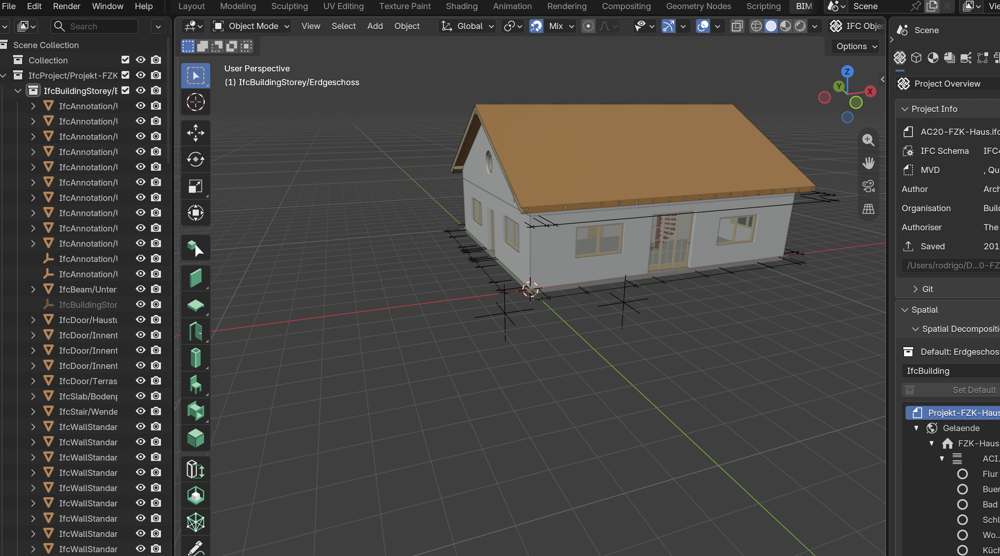

Extract all `IfcElement` entities from the model, record their IFC class `IFC_Type` and `Name`, and aggregate them into a sorted pandas DataFrame df_count showing the exact quantity of each distinct element.

In [38]:
data = []
for elem in model.by_type("IfcElement"):
    data.append({
        "IFC_Type": elem.is_a(),
        "Name": elem.Name if elem.Name else "(No name)",
    })

df_count = (
    pd.DataFrame(data)
    .groupby(["IFC_Type", "Name"], dropna=False)
    .size()
    .reset_index(name="Quantity")
    .sort_values(by="Quantity", ascending=False)
    .reset_index(drop=True)
)

df_count

,IFC_Type,Name,Quantity
0,IfcVirtualElement,(No name),3
1,IfcRailing,(No name),2
2,IfcBeam,First,1
3,IfcBeam,Unterzug-1,1
4,IfcDoor,Haustuer,1
...,...,...,...
94,IfcWindow,EG-Fenster-7,1
95,IfcWindow,EG-Fenster-8,1
96,IfcWindow,EG-Fenster-9,1
97,IfcWindow,OG-Fenster-1,1


Summarize the model's composition by counting the total occurrences of each `IFC_Type` across all `IfcElement` instances, on a dataframe `df_count_name`.

In [39]:
df_count_name = (
    pd.DataFrame([{"IFC_Type": e.is_a() if e.is_a() else "(No Name)"} for e in model.by_type("IfcElement")])
    .value_counts("IFC_Type")
    .reset_index(name="Quantity")
)

df_count_name

,IFC_Type,Quantity
0,IfcMember,42
1,IfcOpeningElement,17
2,IfcWallStandardCase,13
3,IfcWindow,11
4,IfcDoor,5
5,IfcBeam,4
6,IfcSlab,4
7,IfcVirtualElement,3
8,IfcRailing,2
9,IfcStair,1


## Batch Extraction of Element Attributes, Materials, and Property Sets to CSV

This routine loops through the IFC model `AC20-FZK-Haus.ifc` and compiles a flat, tabular dataset `df_properties` across all physical building elements `IfcElement`.

### Extracted Data Pipeline
**Identification & Spatial Containment:** Captures source filename File, IFC entity type IFC_Type, GlobalId and element Name.

**Material Resolution:** Pulls the material from el.get_material() and picks the clearest label available—first Name, then ForLayerSet.LayerSetName for multi-layer setups like IfcMaterialLayerSetUsage.

**Direct Schema Attributes (`attr.<Attribute>`):** Reads non-recursive direct attributes while filtering out internal identifiers, history metadata, placement, and geometry (id, type, GlobalId, Name, OwnerHistory, ObjectPlacement, Representation).

**Property & Quantity Sets (`<PsetName>.<PropName>`):** Calls el.get_psets(elem, psets_only=False) to collect both property sets and quantity sets.

### DataFrame Construction & Export
Consolidates all records into a pandas DataFrame `df_properties` with one row per `IfcElement` and dynamically unioned columns.

Writes the result to `/content/AC20-FZK-Haus_element_properties.csv` and displays the first 5 rows df_properties.head().

In [40]:
import ifcopenshell
import ifcopenshell.util.element as el
import pandas as pd

# Select the IFC files to process
ifc_files = ["/content/AC20-FZK-Haus.ifc"]

rows = []

for file_path in ifc_files:
    m = ifcopenshell.open(file_path)

    # Filter physical building elements, excludes spatial entities like IfcSite, IfcBuilding, IfcBuildingStorey
    for elem in m.by_type("IfcElement"):
        container = el.get_container(elem)
        mat = el.get_material(elem)

        # Resolve material name (handles IfcMaterial, IfcMaterialLayerSetUsage, etc.)
        material_name = (
            getattr(mat, "Name", None)
            or getattr(getattr(mat, "ForLayerSet", None), "LayerSetName", None)
            or (str(mat.is_a()) if mat else None)
        )

        # Extract direct IFC schema attributes, excluding raw geometry and history references
        raw_info = elem.get_info(include_identifier=False, recursive=False)
        direct_attrs = {
            f"attr.{k}": v
            for k, v in raw_info.items()
            if k not in {"id", "type", "GlobalId", "Name", "OwnerHistory", "ObjectPlacement", "Representation"}
        }

        # Extract Property Sets and Quantity Sets from the element and its type
        psets = el.get_psets(elem, psets_only=False)
        flat_props = {}
        for pset_name, props in psets.items():
            for prop_key, prop_val in props.items():
                if prop_key != "id":
                    flat_props[f"{pset_name}.{prop_key}"] = prop_val

        # Combine identification, spatial context, material, direct attributes, and properties
        rows.append({
            "File": file_path.split("/")[-1],
            "IFC_Type": elem.is_a(),
            "GlobalId": elem.GlobalId,
            "Name": elem.Name,
            "Storey": container.Name if container else None,
            "Material": material_name,
            **direct_attrs,
            **flat_props,
        })

# Build the final DataFrame containing all element parameters and properties
df_properties = pd.DataFrame(rows)

# Export the DataFrame to a CSV file
csv_path = "/content/AC20-FZK-Haus_element_properties.csv"
df_properties.to_csv(csv_path, index=False, encoding="utf-8-sig")

print(f"CSV saved to: {csv_path} | Rows: {len(df_properties)} | Columns: {len(df_properties.columns)}")
df_properties.head()

CSV saved to: /content/AC20-FZK-Haus_element_properties.csv | Rows: 102 | Columns: 1297


,File,IFC_Type,GlobalId,Name,Storey,Material,attr.Description,attr.ObjectType,attr.Tag,attr.PredefinedType,...,AC_Equantity_Rundfenster_13.Position Rechts,AC_Equantity_Rundfenster_13.Breite Links,AC_Equantity_Rundfenster_13.Breite Rechts,AC_Equantity_Rundfenster_13.Tiefe Links,AC_Equantity_Rundfenster_13.Tiefe Rechts,AC_Equantity_Rundfenster_13.Öffnungsüberstand links,AC_Equantity_Rundfenster_13.Öffnungsüberstand rechts,AC_Equantity_Rundfenster_13.Öffnungsüberstand oben,AC_Equantity_Rundfenster_13. Öffnungsüberstand unten,AC_Equantity_Rundfenster_13.UK Wand zu Ursprung
0,AC20-FZK-Haus.ifc,IfcBeam,3tCgZT92j6fw8fXgwCL3Jm,Unterzug-1,Erdgeschoss,Radial Gradient Fill 1515460218,None,Radial Gradient Fill 1515460218 200 x 240,EAFC436F-7CDC-482B-8B-93-5FDB86D941A9,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AC20-FZK-Haus.ifc,IfcBeam,0eaC0nL3XAOfFxRXK_2iAr,Pfette-2-1,Dachgeschoss,Solid,None,,542BAFA7-D3B2-4074-B0-AF-859DB4CE679A,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,AC20-FZK-Haus.ifc,IfcBeam,3jZHeNcfvDMf9wG$wx9XqG,Pfette-1-1,Dachgeschoss,Solid,None,,C8707AC7-4260-4F76-A6-95-7665806B676D,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,AC20-FZK-Haus.ifc,IfcBeam,20bTaetQDApP5w8egFxj13,First,Dachgeschoss,Solid,None,,C2B602D2-A015-453B-9E-EF-BB998BB27F3B,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AC20-FZK-Haus.ifc,IfcDoor,1Oms875aH3Wg$9l65H2ZGw,Innentuer-1,Erdgeschoss,IfcMaterialList,None,None,E605AACB-6C4E-458D-93-46-5D9D8C7C21D3,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Other example

In [41]:
import ifcopenshell
import ifcopenshell.util.element as el
import pandas as pd

# Select the IFC files to process
ifc_files = ["/content/Ifc2x3_SampleCastle.ifc"]

rows = []

for file_path in ifc_files:
    m = ifcopenshell.open(file_path)

    # Filter physical building elements, excludes spatial entities like IfcSite, IfcBuilding, IfcBuildingStorey
    for elem in m.by_type("IfcElement"):
        container = el.get_container(elem)
        mat = el.get_material(elem)

        # Resolve material name (handles IfcMaterial, IfcMaterialLayerSetUsage, etc.)
        material_name = (
            getattr(mat, "Name", None)
            or getattr(getattr(mat, "ForLayerSet", None), "LayerSetName", None)
            or (str(mat.is_a()) if mat else None)
        )

        # Extract direct IFC schema attributes, excluding raw geometry and history references
        raw_info = elem.get_info(include_identifier=False, recursive=False)
        direct_attrs = {
            f"attr.{k}": v
            for k, v in raw_info.items()
            if k not in {"id", "type", "GlobalId", "Name", "OwnerHistory", "ObjectPlacement", "Representation"}
        }

        # Extract Property Sets and Quantity Sets from the element and its type
        psets = el.get_psets(elem, psets_only=False)
        flat_props = {}
        for pset_name, props in psets.items():
            for prop_key, prop_val in props.items():
                if prop_key != "id":
                    flat_props[f"{pset_name}.{prop_key}"] = prop_val

        # Combine identification, spatial context, material, direct attributes, and properties
        rows.append({
            "File": file_path.split("/")[-1],
            "IFC_Type": elem.is_a(),
            "GlobalId": elem.GlobalId,
            "Name": elem.Name,
            "Storey": container.Name if container else None,
            "Material": material_name,
            **direct_attrs,
            **flat_props,
        })

# Build the final DataFrame containing all element parameters and properties
df_properties = pd.DataFrame(rows)

# Export the DataFrame to a CSV file
csv_path = "/content/Ifc2x3_SampleCastle_element_properties.csv"
df_properties.to_csv(csv_path, index=False, encoding="utf-8-sig")

print(f"CSV saved to: {csv_path} | Rows: {len(df_properties)} | Columns: {len(df_properties.columns)}")
df_properties.head()

CSV saved to: /content/Ifc2x3_SampleCastle_element_properties.csv | Rows: 3714 | Columns: 6643


,File,IFC_Type,GlobalId,Name,Storey,Material,attr.Description,attr.ObjectType,attr.Tag,eigenschappen.wapening kg/m3,...,AC_Equantity_14047_raam_topgevel.Diepte nis,AC_Equantity_14047_raam_topgevel.Breedte borstwering,AC_Equantity_14047_raam_topgevel.Extra breedte links (gs_parapet_left),AC_Equantity_14047_raam_topgevel.Extra breedte rechts (gs_parapet_right),AC_Equantity_14047_raam_topgevel.Hoogte borstwering,AC_Equantity_14047_raam_topgevel.Overstek onderkant,AC_Equantity_14047_raam_topgevel.AC overmaat links,AC_Equantity_14047_raam_topgevel.AC overmaat rechts,AC_Equantity_14047_raam_topgevel.AC overmaat boven,AC_Equantity_14047_raam_topgevel.AC overmaat onder
0,Ifc2x3_SampleCastle.ifc,IfcBeam,3vSAOyJwTEhQMEIJ6D9qRY,liftputwand,-1 fundering,02 Beton gewapend - ihw,None,IFC_betonopstort_220x345 220 x 345,F970A63C-4FA7-4EAD-A58E-49318D2746E2,,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Ifc2x3_SampleCastle.ifc,IfcBeam,1a49H1hof5wg_s62YvIj$u,fund_strook,-1 fundering,02 Beton gewapend - ihw,None,IFC_strookfundering_2600x550 2600 x 550,64109441-AF2A-45EA-AFB6-1828B94ADFF8,,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Ifc2x3_SampleCastle.ifc,IfcBeam,2501ntWb95m8MEJo4qrYny,fund_opstort,-1 fundering,02 Beton gewapend - ihw,None,IFC_betonopstort_220x315 220 x 315,85001C77-8252-45C0-858E-4F2134D62C7C,,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Ifc2x3_SampleCastle.ifc,IfcBeam,1HNUZLqr52MQIS8JLIpeyr,fund_opstort,-1 fundering,02 Beton gewapend - ihw,None,IFC_betonopstort_370x315 370 x 315,515DE8D5-D351-4259-A49C-213552CE8F35,,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Ifc2x3_SampleCastle.ifc,IfcBeam,3yL4PuBWf5GQngGRpOzQj0,fund_opstort,-1 fundering,02 Beton gewapend - ihw,None,IFC_betonopstort_220x315 220 x 315,FC544678-2E0A-4541-AC6A-41BCD8F5AB40,,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


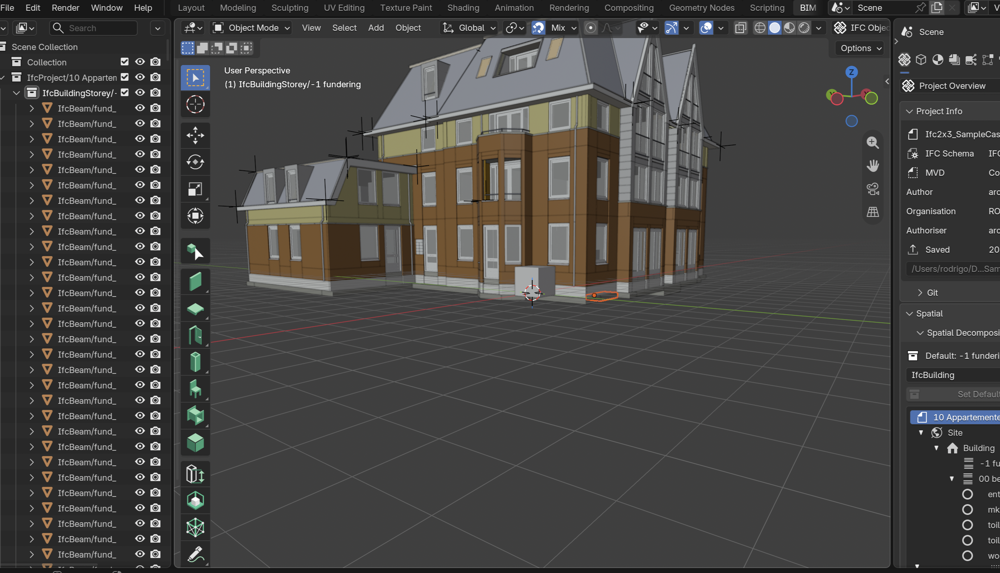

This is another example that uses two IFC files. As a result, the CSV file contains the combined data from both IFC files, including a column that identifies which IFC file the data in each row originated from.

In [42]:
import ifcopenshell
import ifcopenshell.util.element as el
import pandas as pd

# Select the IFC files to process
ifc_files = ["/content/Ifc2x3_SampleCastle.ifc", "/content/AC20-FZK-Haus.ifc"]

rows = []

for file_path in ifc_files:
    m = ifcopenshell.open(file_path)

    # Filter physical building elements, excludes spatial entities like IfcSite, IfcBuilding, IfcBuildingStorey
    for elem in m.by_type("IfcElement"):
        container = el.get_container(elem)
        mat = el.get_material(elem)

        # Resolve material name (handles IfcMaterial, IfcMaterialLayerSetUsage, etc.)
        material_name = (
            getattr(mat, "Name", None)
            or getattr(getattr(mat, "ForLayerSet", None), "LayerSetName", None)
            or (str(mat.is_a()) if mat else None)
        )

        # Extract direct IFC schema attributes, excluding raw geometry and history references
        raw_info = elem.get_info(include_identifier=False, recursive=False)
        direct_attrs = {
            f"attr.{k}": v
            for k, v in raw_info.items()
            if k not in {"id", "type", "GlobalId", "Name", "OwnerHistory", "ObjectPlacement", "Representation"}
        }

        # Extract Property Sets and Quantity Sets from the element and its type
        psets = el.get_psets(elem, psets_only=False)
        flat_props = {}
        for pset_name, props in psets.items():
            for prop_key, prop_val in props.items():
                if prop_key != "id":
                    flat_props[f"{pset_name}.{prop_key}"] = prop_val

        # Combine identification, spatial context, material, direct attributes, and properties
        rows.append({
            "File": file_path.split("/")[-1],
            "IFC_Type": elem.is_a(),
            "GlobalId": elem.GlobalId,
            "Name": elem.Name,
            "Storey": container.Name if container else None,
            "Material": material_name,
            **direct_attrs,
            **flat_props,
        })

# Build the final DataFrame containing all element parameters and properties
df_properties = pd.DataFrame(rows)

# Export the DataFrame to a CSV file
csv_path = "/content/combine_two_ifc_files.csv"
df_properties.to_csv(csv_path, index=False, encoding="utf-8-sig")

print(f"CSV saved to: {csv_path} | Rows: {len(df_properties)} | Columns: {len(df_properties.columns)}")
df_properties.head()

CSV saved to: /content/combine_two_ifc_files.csv | Rows: 3816 | Columns: 7897


,File,IFC_Type,GlobalId,Name,Storey,Material,attr.Description,attr.ObjectType,attr.Tag,eigenschappen.wapening kg/m3,...,AC_Equantity_Rundfenster_13.Position Rechts,AC_Equantity_Rundfenster_13.Breite Links,AC_Equantity_Rundfenster_13.Breite Rechts,AC_Equantity_Rundfenster_13.Tiefe Links,AC_Equantity_Rundfenster_13.Tiefe Rechts,AC_Equantity_Rundfenster_13.Öffnungsüberstand links,AC_Equantity_Rundfenster_13.Öffnungsüberstand rechts,AC_Equantity_Rundfenster_13.Öffnungsüberstand oben,AC_Equantity_Rundfenster_13. Öffnungsüberstand unten,AC_Equantity_Rundfenster_13.UK Wand zu Ursprung
0,Ifc2x3_SampleCastle.ifc,IfcBeam,3vSAOyJwTEhQMEIJ6D9qRY,liftputwand,-1 fundering,02 Beton gewapend - ihw,None,IFC_betonopstort_220x345 220 x 345,F970A63C-4FA7-4EAD-A58E-49318D2746E2,,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Ifc2x3_SampleCastle.ifc,IfcBeam,1a49H1hof5wg_s62YvIj$u,fund_strook,-1 fundering,02 Beton gewapend - ihw,None,IFC_strookfundering_2600x550 2600 x 550,64109441-AF2A-45EA-AFB6-1828B94ADFF8,,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Ifc2x3_SampleCastle.ifc,IfcBeam,2501ntWb95m8MEJo4qrYny,fund_opstort,-1 fundering,02 Beton gewapend - ihw,None,IFC_betonopstort_220x315 220 x 315,85001C77-8252-45C0-858E-4F2134D62C7C,,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Ifc2x3_SampleCastle.ifc,IfcBeam,1HNUZLqr52MQIS8JLIpeyr,fund_opstort,-1 fundering,02 Beton gewapend - ihw,None,IFC_betonopstort_370x315 370 x 315,515DE8D5-D351-4259-A49C-213552CE8F35,,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Ifc2x3_SampleCastle.ifc,IfcBeam,3yL4PuBWf5GQngGRpOzQj0,fund_opstort,-1 fundering,02 Beton gewapend - ihw,None,IFC_betonopstort_220x315 220 x 315,FC544678-2E0A-4541-AC6A-41BCD8F5AB40,,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
